# 04 — Business findings and recommendations

This notebook reads saved outputs from Notebooks 01–03 and generates the executive summary. It does not manually copy results or make new model choices from test outcomes. Findings distinguish descriptive association, model contribution, and causation.

In [1]:
import sys
from pathlib import Path
_base = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(_base))
from scripts.generate_executive_summary import generate
report = generate()
print(report)

# Executive summary

## Scope and question

This project analyzes **12,330 summarized online-shopping sessions** from the UCI Online Shoppers Purchasing Intention Dataset. There were **1,908 purchase sessions**, an observed conversion rate of **15.47%**. The question is which session characteristics are most strongly associated with purchase completion. `Revenue=True` means a purchase occurrence, not dollar revenue.

## Data quality and design

The audit found 0 missing values, 0 invalid boolean values, 0 invalid count/duration measurements, and 125 exact duplicate rows. Exact duplicates were retained because identical session summaries can belong to different users. The seed-42 split contains 7,397 training, 2,465 validation, and 2,468 test rows; validation and test outcomes were reserved for their documented roles.

See the [`data-quality audit`](figures/00_data_quality_audit.png) and
[`split-balance chart`](figures/00_split_balance.png) for visual checks of
the source quality and pa

## Interpretation

The generated report is based only on the current saved audit, descriptive, model, and sensitivity tables. Regenerate it after upstream analysis changes.

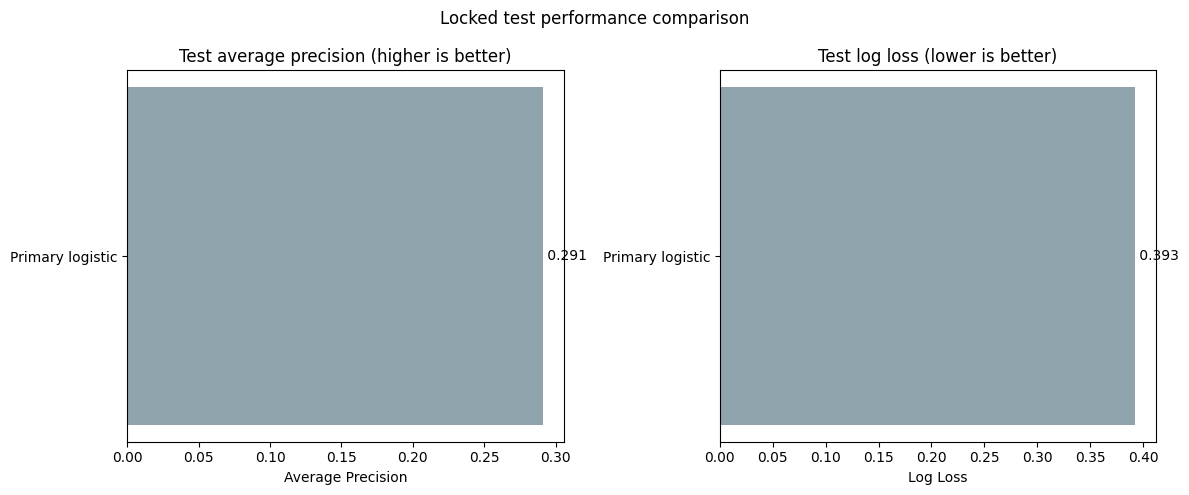

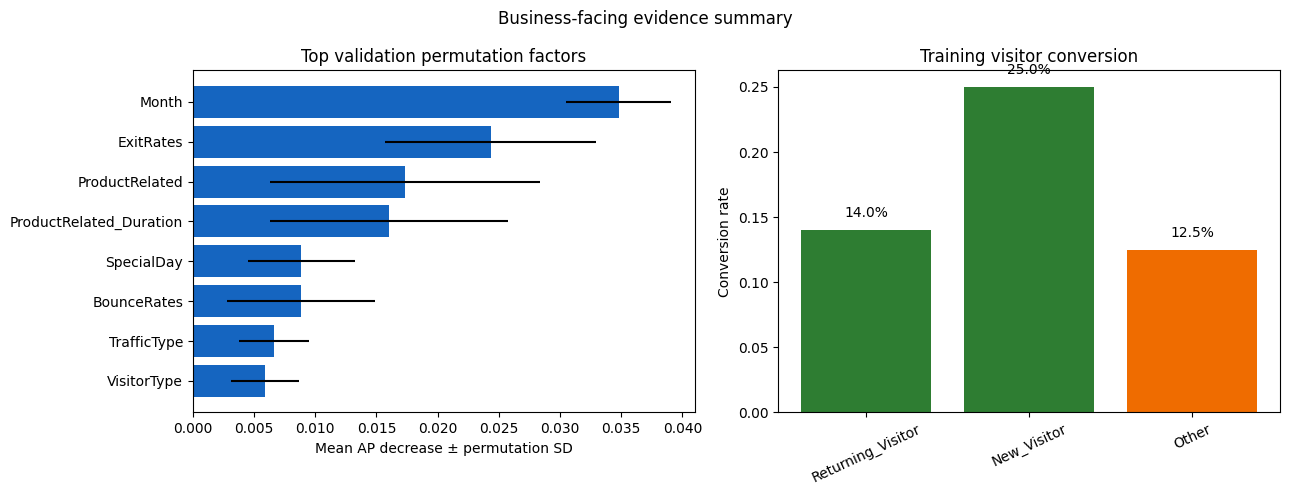

Saved model comparison and business evidence visuals.


In [2]:
from IPython.display import display
# Visual synthesis of saved results
import matplotlib.pyplot as plt
import pandas as pd
from src.data import ROOT

tables = ROOT / 'reports/tables'; figures = ROOT / 'reports/figures'
metrics = pd.read_csv(tables / 'model_metrics.csv')
selected = metrics[metrics['threshold'] < .5].copy()
selected['label'] = selected['model'].replace({'always_no_purchase': 'Always no purchase', 'training_prevalence': 'Training prevalence', 'primary_logistic': 'Primary logistic'})
selected = selected[selected['split'].eq('test')]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric_name, title, lower in [(axes[0], 'average_precision', 'Test average precision (higher is better)', False), (axes[1], 'log_loss', 'Test log loss (lower is better)', True)]:
    ordered = selected.sort_values(metric_name, ascending=lower)
    bars = ax.barh(ordered['label'], ordered[metric_name], color=['#90a4ae', '#6a1b9a', '#1565c0'])
    ax.set_title(title); ax.set_xlabel(metric_name.replace('_', ' ').title())
    for bar, value in zip(bars, ordered[metric_name]): ax.text(value, bar.get_y()+bar.get_height()/2, f' {value:.3f}', va='center')
fig.suptitle('Locked test performance comparison'); fig.tight_layout(); fig.savefig(figures / '13_test_model_comparison.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

importance = pd.read_csv(tables / 'validation_grouped_permutation_importance.csv').head(8).sort_values('mean_ap_decrease')
visitor = pd.read_csv(tables / 'visitor_conversion_training.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(importance['feature'], importance['mean_ap_decrease'], xerr=importance['sd_ap_decrease'], color='#1565c0')
axes[0].set_title('Top validation permutation factors'); axes[0].set_xlabel('Mean AP decrease ± permutation SD')
axes[1].bar(visitor['group'], visitor['conversion_rate'], color=['#2e7d32' if not flag else '#ef6c00' for flag in visitor['low_sample_flag']])
axes[1].set_title('Training visitor conversion'); axes[1].set_ylabel('Conversion rate'); axes[1].tick_params(axis='x', rotation=25)
for i, value in enumerate(visitor['conversion_rate']): axes[1].text(i, value + .01, f'{value:.1%}', ha='center')
fig.suptitle('Business-facing evidence summary'); fig.tight_layout(); fig.savefig(figures / '14_business_evidence_dashboard.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)
print('Saved model comparison and business evidence visuals.')
